# Assignment 3: Parameter-Efficient Fine-Tuning for Urdu Fake News Detection
Group 8, Track 4 (urdu_fake_news), seeds 8 and 108. Models: xlm-roberta-base and google/muril-base-cased.
Methods: Full Fine-Tuning, LoRA, QLoRA, IA3. All runs use the local GTX 1070.

## Setup

In [1]:
import os
os.environ["HF_HOME"] = r"E:\hf_cache"
import pandas as pd
import numpy as np
import re, time, gc
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, BitsAndBytesConfig, set_seed)
from peft import LoraConfig, IA3Config, get_peft_model, prepare_model_for_kbit_training

assert torch.cuda.is_available()
print(torch.cuda.get_device_name(0), "| torch", torch.__version__)

GROUP = 8
TRACK = (GROUP - 1) % 4 + 1
SEEDS = [GROUP, GROUP + 100]
MODELS = {"xlmr": "xlm-roberta-base", "muril": "google/muril-base-cased"}
print("track", TRACK, "seeds", SEEDS)

NVIDIA GeForce GTX 1070 | torch 2.6.0+cu124
track 4 seeds [8, 108]


## Part 1: Data

In [2]:
raw = load_dataset("community-datasets/urdu_fake_news")
df = pd.concat([raw["train"].to_pandas(), raw["test"].to_pandas()], ignore_index=True)
df["news"] = df["news"].astype(str).str.strip()
stats = {"loaded": len(df)}

df = df[df["news"].str.len() > 0]
stats["after empty removal"] = len(df)
df = df.drop_duplicates(subset="news")
stats["after duplicate removal"] = len(df)

def clean(t):
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = t.replace("\u064a", "\u06cc").replace("\u0649", "\u06cc")
    t = t.replace("\u0643", "\u06a9")
    t = t.replace("\u0647", "\u06c1")
    t = re.sub(r"[\u064b-\u065f\u0640]", "", t)
    return re.sub(r"\s+", " ", t).strip()

df["news"] = df["news"].map(clean)
df = df[df["news"].str.len() > 0].reset_index(drop=True)
stats["after cleaning"] = len(df)
print(stats)

train_df, tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=GROUP)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=GROUP)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

names = raw["train"].features["label"].names
dist = pd.DataFrame({s: d["label"].map(dict(enumerate(names))).value_counts()
                     for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}).T
dist["total"] = dist.sum(axis=1)
print(dist)
dist.to_csv("class_distribution.csv")

{'loaded': 900, 'after empty removal': 900, 'after duplicate removal': 894, 'after cleaning': 894}
label  Real  Fake  total
train   346   279    625
val      74    60    134
test     75    60    135


## Part 1: Tokenizer analysis

In [3]:
TOKS = {k: AutoTokenizer.from_pretrained(v) for k, v in MODELS.items()}

def token_stats(tok, texts):
    ids = [tok(t, add_special_tokens=False)["input_ids"] for t in texts]
    n_tokens = sum(len(i) for i in ids)
    n_words = sum(len(t.split()) for t in texts)
    n_unk = sum(i.count(tok.unk_token_id) for i in ids)
    lengths = np.array([len(i) + 2 for i in ids])
    return n_tokens / n_words, n_unk / n_tokens, lengths

texts = train_df["news"].tolist()
fert, unk, lens = {}, {}, {}
for k, tok in TOKS.items():
    fert[k], unk[k], lens[k] = token_stats(tok, texts)

p95 = {k: int(np.percentile(lens[k], 95)) for k in MODELS}
print("95th percentile lengths:", p95)
MAX_LEN = min(max(p95.values()), 512)
print("MAX_LEN =", MAX_LEN)

tok_table = pd.DataFrame({
    "model": list(MODELS.values()),
    "fertility": [fert[k] for k in MODELS],
    "p95_length": [p95[k] for k in MODELS],
    "truncated_pct": [100 * (lens[k] > MAX_LEN).mean() for k in MODELS],
    "unk_pct": [100 * unk[k] for k in MODELS],
})
print(tok_table.round(3))
tok_table.to_csv("tokenizer_table.csv", index=False)

Token indices sequence length is longer than the specified maximum sequence length for this model (913 > 512). Running this sequence through the model will result in indexing errors


Token indices sequence length is longer than the specified maximum sequence length for this model (838 > 512). Running this sequence through the model will result in indexing errors


95th percentile lengths: {'xlmr': 1070, 'muril': 979}
MAX_LEN = 512
                     model  fertility  p95_length  truncated_pct  unk_pct
0         xlm-roberta-base      1.295        1070          24.96    0.000
1  google/muril-base-cased      1.195         979          21.92    0.023


In [4]:
def encode(split_df, tok):
    ds = Dataset.from_dict({"text": split_df["news"].tolist(), "label": split_df["label"].tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

ENC = {k: {"train": encode(train_df, t), "val": encode(val_df, t), "test": encode(test_df, t)}
       for k, t in TOKS.items()}

Map:   0%|          | 0/625 [00:00<?, ? examples/s]

Map:   0%|          | 0/134 [00:00<?, ? examples/s]

Map:   0%|          | 0/135 [00:00<?, ? examples/s]

Map:   0%|          | 0/625 [00:00<?, ? examples/s]

Map:   0%|          | 0/134 [00:00<?, ? examples/s]

Map:   0%|          | 0/135 [00:00<?, ? examples/s]

## Module names of both architectures

In [5]:
for k, name in MODELS.items():
    m = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
    print(k, [n for n, _ in m.named_modules() if ".layer.0." in n and "dropout" not in n.lower() and "LayerNorm" not in n])
    del m

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


xlmr ['roberta.encoder.layer.0.attention', 'roberta.encoder.layer.0.attention.self', 'roberta.encoder.layer.0.attention.self.query', 'roberta.encoder.layer.0.attention.self.key', 'roberta.encoder.layer.0.attention.self.value', 'roberta.encoder.layer.0.attention.output', 'roberta.encoder.layer.0.attention.output.dense', 'roberta.encoder.layer.0.intermediate', 'roberta.encoder.layer.0.intermediate.dense', 'roberta.encoder.layer.0.intermediate.intermediate_act_fn', 'roberta.encoder.layer.0.output', 'roberta.encoder.layer.0.output.dense']


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expe

muril ['bert.encoder.layer.0.attention', 'bert.encoder.layer.0.attention.self', 'bert.encoder.layer.0.attention.self.query', 'bert.encoder.layer.0.attention.self.key', 'bert.encoder.layer.0.attention.self.value', 'bert.encoder.layer.0.attention.output', 'bert.encoder.layer.0.attention.output.dense', 'bert.encoder.layer.0.intermediate', 'bert.encoder.layer.0.intermediate.dense', 'bert.encoder.layer.0.intermediate.intermediate_act_fn', 'bert.encoder.layer.0.output', 'bert.encoder.layer.0.output.dense']


## Part 2: Methods and experiment configurations

In [6]:
EPOCHS = 3
BATCH, ACCUM = 4, 4
LR = {"full": 2e-5, "peft": 2e-4}
L = r".*encoder\.layer\.\d+\."

CONFIGS = {
    "01": dict(method="full"),
    "02": dict(method="lora", r=8, ff=False),
    "03": dict(method="lora", r=16, ff=False),
    "04": dict(method="lora", r=16, ff=True),
    "05": dict(method="qlora", r=16, ff=False, optim="paged_adamw_32bit"),
    "06": dict(method="qlora", r=16, ff=False, optim="adamw_torch"),
    "07a": dict(method="ia3", ff=False),
    "07b": dict(method="ia3", ff=True),
}

def build_model(name, cfg):
    method = cfg["method"]
    if method == "qlora":
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16,
                                 llm_int8_skip_modules=["classifier"])
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=2, quantization_config=bnb, device_map={"": 0})
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    else:
        model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
    if method in ("lora", "qlora"):
        if cfg["ff"]:
            targets = L + r"(attention\.self\.(query|value)|intermediate\.dense|output\.dense)"
        else:
            targets = L + r"attention\.self\.(query|value)"
        model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", r=cfg["r"], lora_alpha=16,
                                                 lora_dropout=0.05, target_modules=targets))
    if method == "ia3":
        if cfg["ff"]:
            targets = L + r"(attention\.self\.(key|value)|output\.dense)"
            ff_modules = L + r"output\.dense"
        else:
            targets = L + r"attention\.self\.(key|value)"
            ff_modules = []
        model = get_peft_model(model, IA3Config(task_type="SEQ_CLS", target_modules=targets,
                                                feedforward_modules=ff_modules))
    return model

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def score(trainer, ds):
    out = trainer.predict(ds)
    pred = out.predictions.argmax(-1)
    return f1_score(out.label_ids, pred, average="macro"), accuracy_score(out.label_ids, pred)

def run(model_key, config_id, frac, seed, exp):
    cfg = CONFIGS[config_id]
    set_seed(seed)
    enc = ENC[model_key]
    train_ds = enc["train"]
    if frac < 1.0:
        idx, _ = train_test_split(np.arange(len(train_df)), train_size=frac,
                                  stratify=train_df["label"], random_state=seed)
        train_ds = train_ds.select(sorted(idx))

    model = build_model(MODELS[model_key], cfg)
    args = TrainingArguments(
        output_dir="tmp_out", num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH,
        gradient_accumulation_steps=ACCUM, per_device_eval_batch_size=16,
        learning_rate=LR["full"] if cfg["method"] == "full" else LR["peft"],
        weight_decay=0.01, warmup_steps=0.1, fp16=True, optim=cfg.get("optim", "adamw_torch"),
        seed=seed, save_strategy="no", eval_strategy="no", logging_strategy="no",
        report_to="none", disable_tqdm=True, remove_unused_columns=False)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds,
                      data_collator=DataCollatorWithPadding(TOKS[model_key]))

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    trainer.train()
    train_time = time.time() - start
    peak_mb = torch.cuda.max_memory_allocated() / 2**20
    trainable = count_trainable(model)

    val_f1, _ = score(trainer, enc["val"])
    test_f1, test_acc = score(trainer, enc["test"])
    row = dict(model=model_key, exp=exp, config=config_id, method=cfg["method"], frac=frac, seed=seed,
               val_f1=val_f1, f1=test_f1, acc=test_acc, time_s=train_time,
               mem_mb=peak_mb, trainable=trainable)
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return row

## Part 3: Experiments 01 to 07 (all configurations, both models, both seeds)

In [7]:
RESULTS = "results.csv"
rows = pd.read_csv(RESULTS).to_dict("records") if os.path.exists(RESULTS) else []
done = {(r["model"], r["config"], r["frac"], r["seed"]) for r in rows}

def run_and_log(model_key, config_id, frac, seed, exp):
    if (model_key, config_id, frac, seed) in done:
        return
    row = run(model_key, config_id, frac, seed, exp)
    rows.append(row)
    done.add((model_key, config_id, frac, seed))
    pd.DataFrame(rows).to_csv(RESULTS, index=False)
    print(f"{model_key:6s} exp {exp:3s} cfg {config_id:3s} frac {frac:.2f} seed {seed:3d} | "
          f"f1 {row['f1']:.4f} acc {row['acc']:.4f} time {row['time_s']:.0f}s mem {row['mem_mb']:.0f}MB")

for seed in SEEDS:
    for model_key in MODELS:
        for config_id in CONFIGS:
            run_and_log(model_key, config_id, 1.0, seed, config_id)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '203.2', 'train_samples_per_second': '9.226', 'train_steps_per_second': '0.59', 'train_loss': '2.708', 'epoch': '3'}


xlmr   exp 01  cfg 01  frac 1.00 seed   8 | f1 0.3571 acc 0.5556 time 203s mem 5366MB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (118 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expe

{'train_runtime': '151.8', 'train_samples_per_second': '12.35', 'train_steps_per_second': '0.79', 'train_loss': '2.714', 'epoch': '3'}


muril  exp 07b cfg 07b frac 1.00 seed 108 | f1 0.3571 acc 0.5556 time 152s mem 2055MB


## Experiment 08: data size with the best configuration of each method (chosen by validation macro-F1)

In [8]:
full_runs = pd.DataFrame(rows)
full_runs = full_runs[full_runs["frac"] == 1.0]
BEST = {m: g.groupby("config")["val_f1"].mean().idxmax() for m, g in full_runs.groupby("method")}
print(BEST)

for seed in SEEDS:
    for model_key in MODELS:
        for method, config_id in BEST.items():
            for frac in [0.25, 0.5]:
                run_and_log(model_key, config_id, frac, seed, "08")

{'full': '01', 'ia3': '07a', 'lora': '02', 'qlora': '05'}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '50.69', 'train_samples_per_second': '9.232', 'train_steps_per_second': '0.592', 'train_loss': '2.702', 'epoch': '3'}


xlmr   exp 08  cfg 01  frac 0.25 seed   8 | f1 0.3571 acc 0.5556 time 51s mem 5381MB


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (119 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expe

{'train_runtime': '79.04', 'train_samples_per_second': '11.84', 'train_steps_per_second': '0.759', 'train_loss': '2.699', 'epoch': '3'}


muril  exp 08  cfg 05  frac 0.50 seed 108 | f1 0.3571 acc 0.5556 time 79s mem 1465MB


## Results

In [9]:
res = pd.DataFrame(rows)
res.to_csv(RESULTS, index=False)
cols = ["f1", "acc", "time_s", "mem_mb", "trainable"]
summary = res.groupby(["model", "exp", "config", "method", "frac"])[cols].agg(["mean", "std"])
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index()
summary.to_csv("results_summary.csv", index=False)
summary.round(4)

,model,exp,config,method,frac,f1_mean,f1_std,acc_mean,acc_std,time_s_mean,time_s_std,mem_mb_mean,mem_mb_std,trainable_mean,trainable_std
0,muril,01,01,full,1.00,0.3571,0.0000,0.5556,0.0000,195.7840,8.1928,4709.2783,7.1774,237557762.0,0.0
1,muril,02,02,lora,1.00,0.3571,0.0000,0.5556,0.0000,146.4355,4.4404,1774.2305,0.6905,296450.0,0.0
2,muril,03,03,lora,1.00,0.3571,0.0000,0.5556,0.0000,145.6064,3.1649,1778.8296,0.0000,591362.0,0.0
3,muril,04,04,lora,1.00,0.3571,0.0000,0.5556,0.0000,164.7123,1.0869,2110.6030,7.7782,2065922.0,0.0
4,muril,05,05,qlora,1.00,0.3571,0.0000,0.5556,0.0000,156.6408,1.4258,1467.3801,5.8540,591362.0,0.0
5,muril,06,06,qlora,1.00,0.3571,0.0000,0.5556,0.0000,155.0887,0.6422,1467.3801,5.8540,591362.0,0.0
6,muril,07a,07a,ia3,1.00,0.3571,0.0000,0.5556,0.0000,141.4778,0.0587,1729.2344,1.8610,19970.0,0.0
7,muril,07b,07b,ia3,1.00,0.3571,0.0000,0.5556,0.0000,151.5751,0.5767,2057.4045,3.8943,56834.0,0.0
8,muril,08,01,full,0.25,0.4819,0.1764,0.5815,0.0367,49.3308,1.4426,4712.0547,0.9723,237557762.0,0.0
9,muril,08,01,full,0.50,0.3571,0.0000,0.5556,0.0000,97.6880,0.3353,4712.9641,0.3138,237557762.0,0.0


## Part 3: Required plots

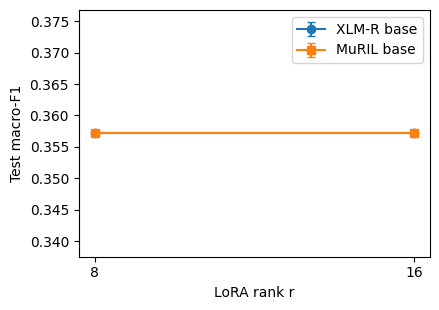

In [10]:
LABEL = {"xlmr": "XLM-R base", "muril": "MuRIL base"}
COLOR = {"full": "tab:blue", "lora": "tab:orange", "qlora": "tab:green", "ia3": "tab:red"}
MARK = {"xlmr": "o", "muril": "s"}
S = summary[summary["frac"] == 1.0]

fig, ax = plt.subplots(figsize=(4.5, 3.2))
for k in MODELS:
    d = S[(S["model"] == k) & S["config"].isin(["02", "03"])].sort_values("config")
    ax.errorbar([8, 16], d["f1_mean"], yerr=d["f1_std"], marker=MARK[k], capsize=3, label=LABEL[k])
ax.set_xticks([8, 16]); ax.set_xlabel("LoRA rank r"); ax.set_ylabel("Test macro-F1"); ax.legend()
plt.tight_layout(); plt.savefig("plot_lora_rank.png", dpi=200); plt.show()

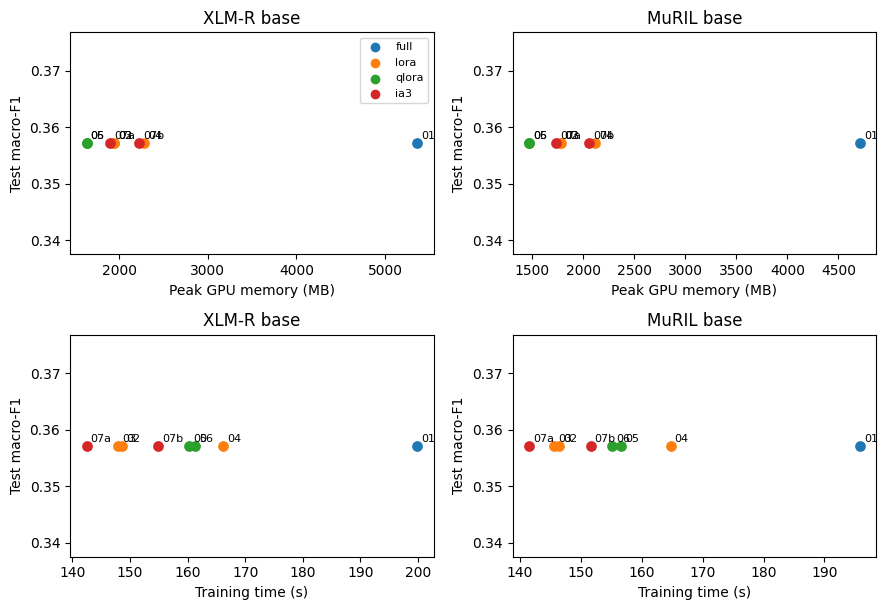

In [11]:
def front(x, y):
    keep = [i for i in range(len(x)) if not any((x[j] <= x[i] and y[j] >= y[i]) and (x[j] < x[i] or y[j] > y[i])
                                                  for j in range(len(x)))]
    keep.sort(key=lambda i: x[i])
    return [x[i] for i in keep], [y[i] for i in keep]

fig, axes = plt.subplots(2, 2, figsize=(9, 6.2))
for r, (col, xlabel) in enumerate([("mem_mb", "Peak GPU memory (MB)"), ("time_s", "Training time (s)")]):
    for c, k in enumerate(MODELS):
        ax = axes[r, c]
        d = S[S["model"] == k].reset_index(drop=True)
        for _, row in d.iterrows():
            ax.scatter(row[col + "_mean"], row["f1_mean"], color=COLOR[row["method"]], s=45)
            ax.annotate(row["config"], (row[col + "_mean"], row["f1_mean"]), fontsize=8,
                        xytext=(3, 3), textcoords="offset points")
        fx, fy = front(d[col + "_mean"].tolist(), d["f1_mean"].tolist())
        ax.step(fx, fy, where="post", color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel(xlabel); ax.set_ylabel("Test macro-F1"); ax.set_title(LABEL[k])
for m, c in COLOR.items():
    axes[0, 0].scatter([], [], color=c, label=m)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("plot_pareto.png", dpi=200); plt.show()

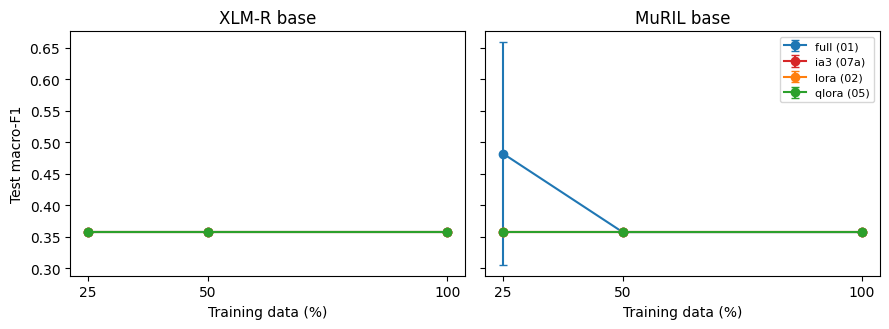

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, k in zip(axes, MODELS):
    for method, config_id in BEST.items():
        d = summary[(summary["model"] == k) & (summary["config"] == config_id)].sort_values("frac")
        ax.errorbar(d["frac"] * 100, d["f1_mean"], yerr=d["f1_std"], marker="o", capsize=3,
                    color=COLOR[method], label=f"{method} ({config_id})")
    ax.set_xticks([25, 50, 100]); ax.set_xlabel("Training data (%)"); ax.set_title(LABEL[k])
axes[0].set_ylabel("Test macro-F1"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("plot_data_size.png", dpi=200); plt.show()

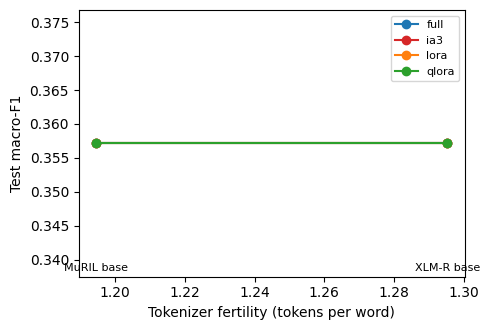

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.4))
for method, config_id in BEST.items():
    d = S[S["config"] == config_id].set_index("model").loc[list(MODELS)]
    ax.plot([fert[k] for k in MODELS], d["f1_mean"], marker="o", color=COLOR[method], label=method)
ax.set_xlabel("Tokenizer fertility (tokens per word)"); ax.set_ylabel("Test macro-F1"); ax.legend(fontsize=8)
for k in MODELS:
    ax.annotate(LABEL[k], (fert[k], ax.get_ylim()[0]), fontsize=8, xytext=(0, 4), textcoords="offset points", ha="center")
plt.tight_layout(); plt.savefig("plot_fertility.png", dpi=200); plt.show()

## Tables for the report

In [14]:
def pm(m, s, f="{:.3f}"):
    return (f + " $\\pm$ " + f).format(m, 0 if pd.isna(s) else s)

LABELS = {"01": "Full FT", "02": "LoRA r=8, attn", "03": "LoRA r=16, attn", "04": "LoRA r=16, attn+FF",
          "05": "QLoRA r=16, paged", "06": "QLoRA r=16, not paged", "07a": "IA3 attn", "07b": "IA3 attn+FF"}

def main_table(k):
    d = summary[summary["model"] == k]
    lines = []
    for _, r in d[d["frac"] == 1.0].sort_values("config").iterrows():
        lines.append((r["config"], LABELS[r["config"]], r))
    for _, r in d[d["exp"] == "08"].sort_values(["method", "frac"]).iterrows():
        lines.append(("08", f"{r['method']} ({r['config']}), {int(r['frac'] * 100)}\\% data", r))
    out = []
    for e, name, r in lines:
        out.append(" & ".join([e, name, pm(r["f1_mean"], r["f1_std"]), pm(r["acc_mean"], r["acc_std"]),
                               pm(r["time_s_mean"], r["time_s_std"], "{:.0f}"),
                               pm(r["mem_mb_mean"] / 1024, r["mem_mb_std"] / 1024, "{:.2f}"),
                               f"{r['trainable_mean'] / 1e6:.3f}"]) + r" \\")
    return "\n".join(out)

for k in MODELS:
    open(f"table_{k}.tex", "w", encoding="utf-8").write(main_table(k))

t = tok_table.copy()
open("table_tokenizer.tex", "w", encoding="utf-8").write("\n".join(
    f"{r.model} & {r.fertility:.3f} & {r.p95_length} & {r.truncated_pct:.1f} & {r.unk_pct:.4f}" + r" \\"
    for r in t.itertuples()))
open("table_dist.tex", "w", encoding="utf-8").write("\n".join(
    f"{s} & {int(r['Fake'])} & {int(r['Real'])} & {int(r['total'])}" + r" \\" for s, r in dist.iterrows()))
print(open("table_xlmr.tex", encoding="utf-8").read())

01 & Full FT & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 200 $\pm$ 5 & 5.24 $\pm$ 0.01 & 278.045 \\
02 & LoRA r=8, attn & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 149 $\pm$ 7 & 1.89 $\pm$ 0.00 & 0.887 \\
03 & LoRA r=16, attn & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 148 $\pm$ 5 & 1.90 $\pm$ 0.00 & 1.182 \\
04 & LoRA r=16, attn+FF & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 166 $\pm$ 2 & 2.23 $\pm$ 0.00 & 2.657 \\
05 & QLoRA r=16, paged & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 160 $\pm$ 0 & 1.59 $\pm$ 0.00 & 1.182 \\
06 & QLoRA r=16, not paged & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 161 $\pm$ 3 & 1.59 $\pm$ 0.00 & 1.182 \\
07a & IA3 attn & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 142 $\pm$ 0 & 1.85 $\pm$ 0.00 & 0.611 \\
07b & IA3 attn+FF & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 155 $\pm$ 4 & 2.17 $\pm$ 0.00 & 0.647 \\
08 & full (01), 25\% data & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.000 & 50 $\pm$ 1 & 5.26 $\pm$ 0.00 & 278.045 \\
08 & full (01), 50\% data & 0.357 $\pm$ 0.000 & 0.556 $\pm$ 0.0